# 04 Evaluation of the baseline methods
This notebook scores three methods against the ratings made for the 30 development products. Nothing here changes the methods; it only measures them.

**The three methods**
- **Baseline:** title (TF-IDF) plus all attributes, with the starting weights.
- **Title only:** the title comparison alone.
- **Attributes only:** everything except the title.

**How results are judged:** each returned result gets the 0, 1 or 2 given by the rater. The main score is **nDCG@10**, which rewards putting strong matches near the top of the 10 results. **Precision@10** is the share of the 10 results rated at least 1.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

from product_similarity import evaluation as ev
from product_similarity.judging import comparison_methods
from product_similarity.service import build_engine

root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
plt.rcParams.update(
    {"figure.figsize": (7, 3.5), "axes.spines.top": False, "axes.spines.right": False}
)
BLUE, GREY, ORANGE, GREEN = "#4c78a8", "#c7c7c7", "#f58518", "#54a24b"
pd.set_option("display.max_colwidth", 60)
pd.set_option("display.width", 170)

engine = build_engine(archive=root / "data" / "archive.zip")
methods = comparison_methods(engine.products, engine.id_map)
queries = json.loads((root / "evaluation/queries.json").read_text(encoding="utf-8"))
dev = {q["query_no"]: q for q in queries if q["split"] == "dev"}
grades = ev.load_grades(root / "evaluation/judgments/dev_grades.csv")
by_id = {p.uniq_id: p for p in engine.products}

ranked = {
    name: {no: m.find_similar(q["id"], ev.K) for no, q in dev.items()}
    for name, m in methods.items()
}
per_query = {name: ev.score_method(r, grades) for name, r in ranked.items()}
summary = {name: ev.summarise(s) for name, s in per_query.items()}
print(f"{len(dev)} development products, {sum(len(g) for g in grades.values())} rated results")

30 development products, 720 rated results


## 1. The ratings
The rater graded results for all 30 development products.

**How the ratings were made.** Each result was shown as a card with its picture, title, brand, category and price, and rated 0, 1 or 2 in a browser page. The page did not say which method found a result. This is the page while rating (720 of 729 results rated):

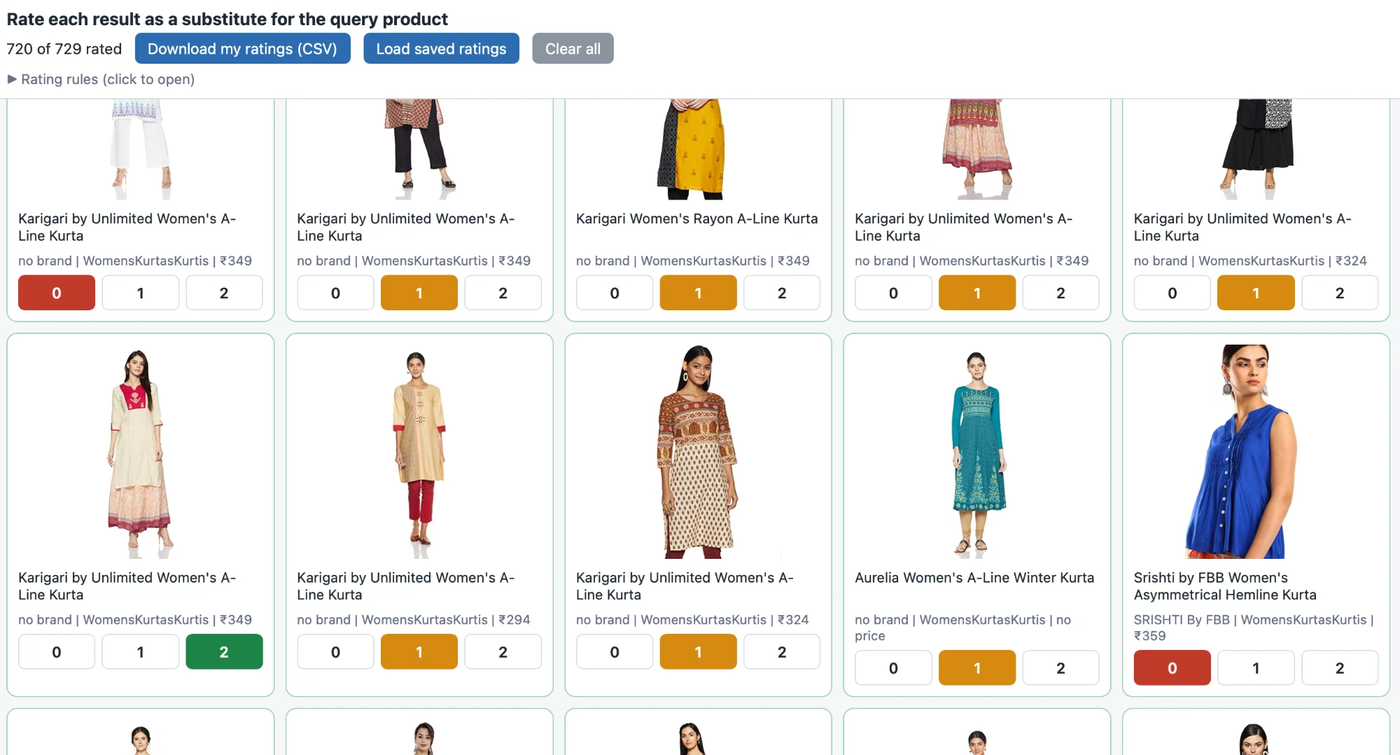

In [ ]:
from IPython.display import Image

display(Image(filename=root / "evaluation" / "rating_page.png", width=900))

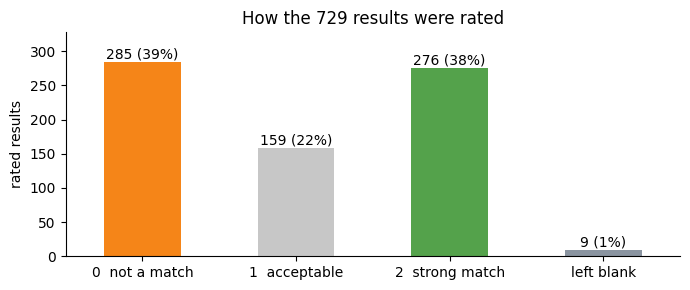

In [2]:
import csv

with open(root / "evaluation/judgments/dev_grades.csv", newline="", encoding="utf-8") as handle:
    rows = list(csv.DictReader(handle))
counts = (
    pd.Series([r["grade"] or "left blank" for r in rows])
    .value_counts()
    .reindex(["0", "1", "2", "left blank"])
)
labels = ["0  not a match", "1  acceptable", "2  strong match", "left blank"]
ax = counts.plot.bar(color=[ORANGE, GREY, GREEN, "#8a94a0"], rot=0, figsize=(7, 3))
ax.set_xticklabels(labels)
for i, v in enumerate(counts):
    ax.text(i, v + 5, f"{v} ({v / len(rows):.0%})", ha="center")
ax.set_ylim(0, counts.max() * 1.15)
ax.set_ylabel("rated results")
ax.set_title("How the 729 results were rated")
plt.tight_layout()
plt.show()

### What this shows
Two in five results were rated a strong match and about four in ten were rated not a match, so the pooled results contain both good and bad answers.

## 2. Scoreboard
Mean score over the 30 products, with a 95% range from resampling the products.

,nDCG@10,range,precision@10,strong precision@10
baseline,0.723,0.64 to 0.81,0.74,0.537
title_only,0.573,0.48 to 0.67,0.55,0.417
attributes_only,0.475,0.38 to 0.56,0.62,0.320


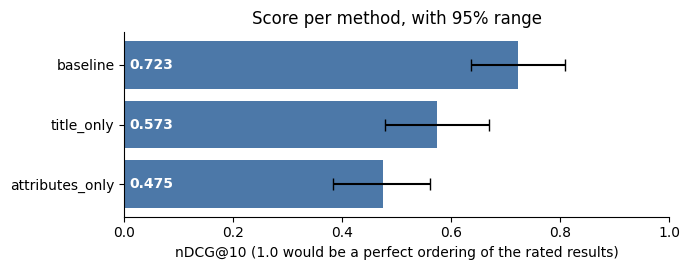

In [3]:
table = pd.DataFrame(summary).T
board = pd.DataFrame(
    {
        "nDCG@10": table["ndcg_at_10"],
        "range": [
            f"{lo:.2f} to {hi:.2f}"
            for lo, hi in zip(table["ndcg_at_10_low"], table["ndcg_at_10_high"])
        ],
        "precision@10": table["precision_at_10"],
        "strong precision@10": table["strong_precision_at_10"],
    }
).round(3)
display(board)

fig, ax = plt.subplots(figsize=(7, 2.8))
names = list(summary)
means = [summary[n]["ndcg_at_10"] for n in names]
errors = [
    [summary[n]["ndcg_at_10"] - summary[n]["ndcg_at_10_low"] for n in names],
    [summary[n]["ndcg_at_10_high"] - summary[n]["ndcg_at_10"] for n in names],
]
ax.barh(names[::-1], means[::-1], xerr=[e[::-1] for e in errors], color=BLUE, capsize=4)
for i, v in enumerate(means[::-1]):
    ax.text(0.01, i, f"{v:.3f}", va="center", color="white", fontweight="bold")
ax.set_xlim(0, 1)
ax.set_xlabel("nDCG@10 (1.0 would be a perfect ordering of the rated results)")
ax.set_title("Score per method, with 95% range")
plt.tight_layout()
plt.show()

### What this shows
The baseline scores highest, and the other two are lower. The bars show a range, not a single point: with only 30 products, a score could move by about 0.08 either way, so the ranges matter more than the exact numbers.

## 3. Are the differences real or luck?
For each pair of methods, the difference in nDCG@10 on the same products, with a 95% range. If the range does not cross zero, the difference is unlikely to be luck.

,comparison,difference,low,high,verdict
0,baseline minus title_only,0.150,0.037,0.254,real
1,baseline minus attributes_only,0.248,0.168,0.334,real
2,title_only minus attributes_only,0.098,-0.028,0.223,could be luck


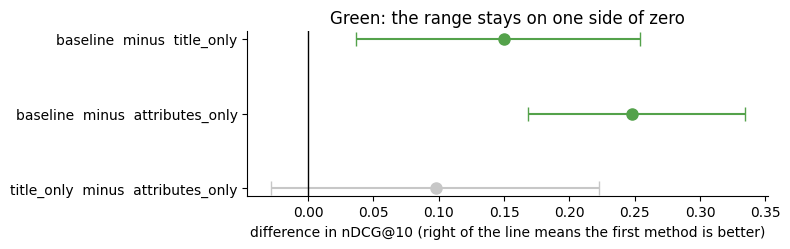

In [4]:
ndcg = {
    n: {q: s["ndcg"] for q, s in r.items() if s["ndcg"] is not None} for n, r in per_query.items()
}
pairs = [
    ("baseline", "title_only"),
    ("baseline", "attributes_only"),
    ("title_only", "attributes_only"),
]
diff = []
for a, b in pairs:
    mean, low, high = ev.paired_difference(ndcg[a], ndcg[b])
    diff.append(
        (f"{a}  minus  {b}", mean, low, high, "real" if low > 0 or high < 0 else "could be luck")
    )
frame = pd.DataFrame(diff, columns=["comparison", "difference", "low", "high", "verdict"]).round(3)
display(frame)
fig, ax = plt.subplots(figsize=(8, 2.6))
for i, (_label, mean, low, high, verdict) in enumerate(diff[::-1]):
    colour = GREEN if verdict == "real" else GREY
    ax.errorbar(
        mean, i, xerr=[[mean - low], [high - mean]], fmt="o", color=colour, capsize=5, markersize=8
    )
ax.axvline(0, color="black", linewidth=1)
ax.set_yticks(range(len(diff)))
ax.set_yticklabels([d[0] for d in diff[::-1]])
ax.set_xlabel("difference in nDCG@10 (right of the line means the first method is better)")
ax.set_title("Green: the range stays on one side of zero")
plt.tight_layout()
plt.show()

### What this shows
The baseline beats both the title-only method and the attributes-only method, and both ranges stay above zero. Title-only versus attributes-only cannot be separated: that range crosses zero, so with 30 products we cannot say which of the two is better.

## 4. By kind of product
The 30 products were chosen from seven groups. Each group has only three to eight products, so treat this as a hint.

method,products,baseline,title_only,attributes_only
group,,,,
common category,8,0.63,0.45,0.44
complete data,5,0.91,0.64,0.72
high price,2,0.31,0.61,0.06
low price,2,0.30,0.50,0.28
rare category,3,0.97,0.83,0.56
repeated title,5,0.70,0.68,0.51
sparse data,5,0.89,0.46,0.45


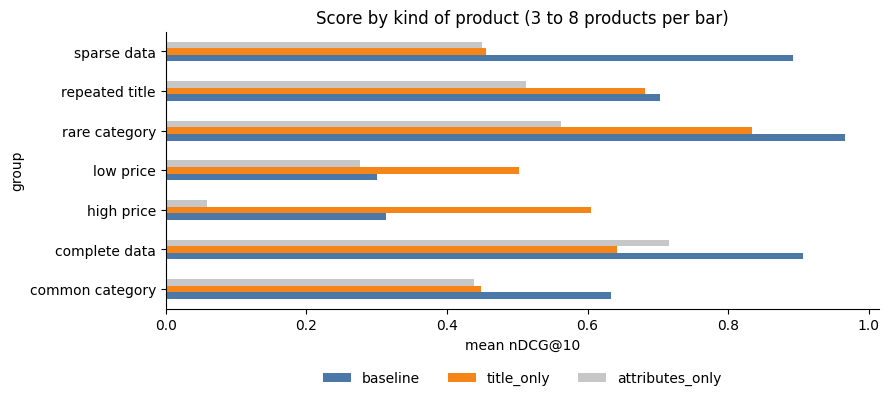

In [5]:
groups = {no: q["group"] for no, q in dev.items()}
rows = []
for name, scores in per_query.items():
    for no, s in scores.items():
        if s["ndcg"] is not None:
            rows.append((name, groups[no], s["ndcg"]))
frame = pd.DataFrame(rows, columns=["method", "group", "ndcg"])
pivot = frame.pivot_table(index="group", columns="method", values="ndcg", aggfunc="mean")[
    list(methods)
]
counts = frame[frame["method"] == "baseline"].groupby("group").size()
pivot.insert(0, "products", counts)
display(pivot.round(2))
ax = pivot.drop(columns="products").plot.barh(figsize=(9, 4.2), color=[BLUE, ORANGE, GREY])
ax.set_xlabel("mean nDCG@10")
ax.set_title("Score by kind of product (3 to 8 products per bar)")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=3, frameon=False)
plt.tight_layout()
plt.show()

### What this shows
The baseline is ahead in five of the seven groups, and the biggest gain is on **sparse data** (0.89 against 0.46 and 0.45), where neither the title nor the attributes alone are enough. It is **behind title-only in both price groups**, but each of those groups has only two products, so that is a hint to check later, not a finding. Small groups are noisy, so no single bar here is firm.

## 5. Where the methods disagree most
The products where the baseline did far better, and far worse, than title-only. Each result shows the rating it received.

In [6]:
def show(no, name, n=6):
    q = dev[no]
    print(
        f"{no}: {by_id[q['id']].title[:75]}  [{q['group']}]  nDCG {per_query[name][no]['ndcg']:.2f}"
    )
    for cid in ranked[name][no][:n]:
        g = grades[no].get(cid, "unrated")
        print(f"    rated {g}   {by_id[cid].title[:68]}  [{by_id[cid].category}]")


gap = {
    no: per_query["baseline"][no]["ndcg"] - per_query["title_only"][no]["ndcg"]
    for no in dev
    if per_query["baseline"][no]["ndcg"] is not None
    and per_query["title_only"][no]["ndcg"] is not None
}
best, worst = max(gap, key=gap.get), min(gap, key=gap.get)
print("=== Baseline much better than title only ===")
show(best, "baseline")
print("  --- title only:")
show(best, "title_only")
print()
print("=== Baseline worse than title only ===")
show(worst, "baseline")
print("  --- title only:")
show(worst, "title_only")

=== Baseline much better than title only ===
Q26: Tommy Hilfiger Men's Core Neat I Tie  [sparse data]  nDCG 0.95
    rated 2   Tommy Hilfiger Men's Double Thin-Stripe Tie  [MensNeckties]
    rated 2   Dockers Men's Filbert Street Neat 100% Silk Tie  [MensNeckties]
    rated 2   Blacksmith Red Tie for Men - Black Tie for Men - Green Tie for Men -  [MensNeckties]
    rated 2   Men's red and black slim tie combo  [MensNeckties]
    rated 2   tie Blue tie red tie Brown tie Grey tie Red set Formal Single Colour  [MensNeckties]
    rated 1   Tommy Hilfiger Men's Core Solid Bow Tie  [MensBowTies]
  --- title only:
Q26: Tommy Hilfiger Men's Core Neat I Tie  [sparse data]  nDCG 0.07
    rated 1   Tommy Hilfiger Men's Core Solid Bow Tie  [MensBowTies]
    rated 0   TOMMY HILFIGER Men's Casual Shirt  [MensCasualShirts]
    rated 0   TOMMY HILFIGER Men's Casual Shirt  [MensCasualShirts]
    rated 0   TOMMY HILFIGER Men's Casual Shirt  [MensCasualShirts]
    rated 0   TOMMY HILFIGER Men's Casual Sh

### What this shows
- **Where the baseline wins (Q26):** title-only is pulled to other Tommy Hilfiger products, such as shirts, because they share the brand name. The category and audience in the baseline keep it on neckties.
- **Where it loses (Q49):** the neck warmer is filed in the data under **men's T-shirts**, which is a wrong label. The baseline follows the label and returns T-shirts, while title-only follows the words "neck warmer" and "gaiter". So a wrong category in the data can pull the baseline off course.

## 6. How far to trust this

In [7]:
print("30 development products were rated by one person, so the labels reflect one judgment.")

30 development products were rated by one person, so the labels reflect one judgment.


- **One rater.** The ratings are one person's judgment.
- **30 products.** Small differences between methods cannot be told apart.
- **Development set only.** The 20 locked products have not been rated or used.

## 7. Recorded in MLflow
Every scoring run was saved in **MLflow**, a tool that keeps a log of experiments, so each result can be traced back and compared later. For each method, one run records:

- **Settings:** the method name and its weights, the number of results scored (top 10), and the number of products.
- **Scores:** nDCG@10 and precision@10, each with its 95% range.
- **Fingerprints:** short hashes of the dataset and the ratings file, plus the git commit, so the result points to the exact files and code that produced it.
- **Notes:** the limitations, saved as tags on the run, and the exported result files.

MLflow is used only for tracking. The web service does not use it, and it is not in the Docker image. This is MLflow's comparison page for our three methods:

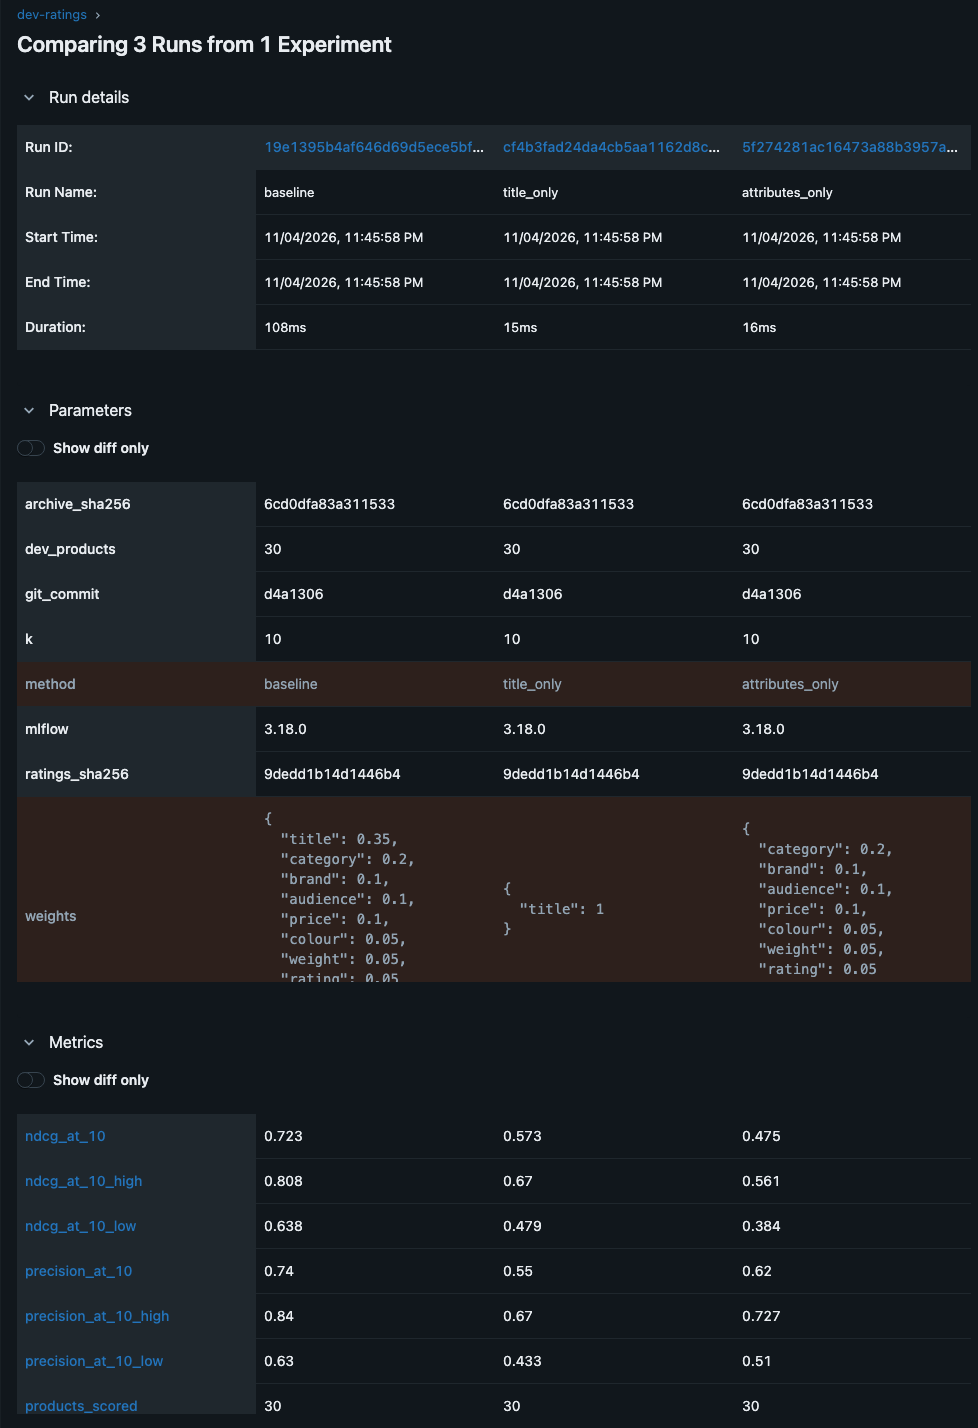

In [ ]:
from IPython.display import Image

display(Image(filename=root / "evaluation" / "mlflow_runs.png", width=900))

To open it: `pip install -e ".[experiments]"`, `python experiments/run_evaluation.py`, then `mlflow ui --backend-store-uri sqlite:///mlflow.db --port 5055`, and click **Model training** at http://127.0.0.1:5055.

## 8. Conclusion

**Goal:** measure which method gives better results, using ratings by a person, before tuning anything.

**1. How I measured it**
- **What I did:** I rated 729 pooled results for 30 products. The results came from three methods and were mixed and shuffled, so I could not tell which method found which.
- **How the score works:** each method's top 10 is scored against my ratings, using nDCG@10 (strong matches near the top count most) and precision@10.
- **Why:** there is no answer key in the data, so a person's judgment is the only way to know what is good.
- **Recorded:** every run is saved in MLflow with its settings, scores, data fingerprints and limitations, as shown in section 7.

**2. The mix beats each part**
- **Result:** the baseline scores 0.72, against 0.57 for the title alone and 0.48 for the attributes alone.
- **Why it matters:** combining the title with the attributes helps, and the gap is larger than luck (next point).

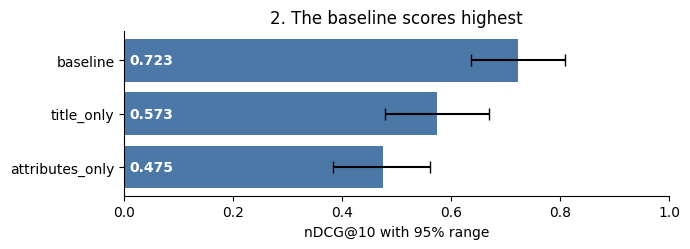

In [8]:
fig, ax = plt.subplots(figsize=(7, 2.6))
names = list(summary)
means = [summary[n]["ndcg_at_10"] for n in names]
low = [summary[n]["ndcg_at_10"] - summary[n]["ndcg_at_10_low"] for n in names]
high = [summary[n]["ndcg_at_10_high"] - summary[n]["ndcg_at_10"] for n in names]
ax.barh(names[::-1], means[::-1], xerr=[low[::-1], high[::-1]], color=BLUE, capsize=4)
for i, v in enumerate(means[::-1]):
    ax.text(0.01, i, f"{v:.3f}", va="center", color="white", fontweight="bold")
ax.set_xlim(0, 1)
ax.set_xlabel("nDCG@10 with 95% range")
ax.set_title("2. The baseline scores highest")
plt.tight_layout()
plt.show()

**3. Which differences are real**
- **Result:** the baseline is better than each part alone, and both gaps stay clear of zero. Title-only and attributes-only can not be told apart with 30 products.
- **Why it matters:** I can say the mix is better, but not which of the two parts is the stronger one.

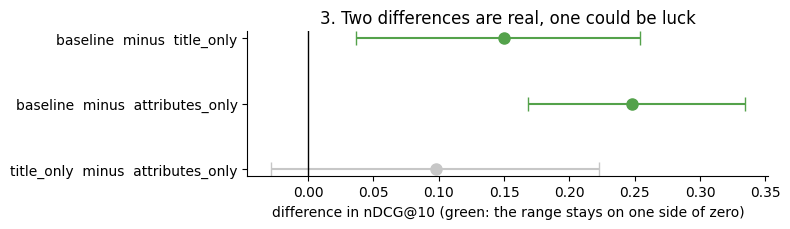

In [9]:
fig, ax = plt.subplots(figsize=(8, 2.4))
for i, (_label, mean, lo, hi, verdict) in enumerate(diff[::-1]):
    ax.errorbar(
        mean,
        i,
        xerr=[[mean - lo], [hi - mean]],
        fmt="o",
        capsize=5,
        markersize=8,
        color=GREEN if verdict == "real" else GREY,
    )
ax.axvline(0, color="black", linewidth=1)
ax.set_yticks(range(len(diff)))
ax.set_yticklabels([d[0] for d in diff[::-1]])
ax.set_xlabel("difference in nDCG@10 (green: the range stays on one side of zero)")
ax.set_title("3. Two differences are real, one could be luck")
plt.tight_layout()
plt.show()

**4. Where combining helps most**
- **Result:** on products with little data, the baseline scores 0.89 and each part alone scores about 0.46.
- **Why:** when little is known, neither the title nor the attributes are enough, and together they are.
- **Caution:** the baseline is behind title-only in the two price groups, but each group has only two products.

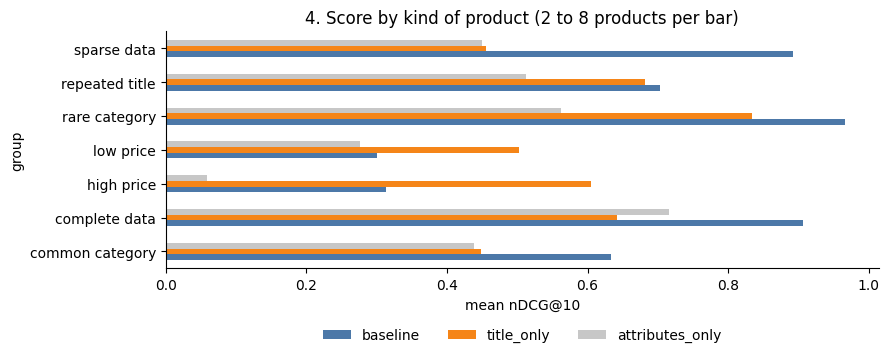

In [10]:
ax = pivot.drop(columns="products").plot.barh(figsize=(9, 3.8), color=[BLUE, ORANGE, GREY])
ax.set_xlabel("mean nDCG@10")
ax.set_title("4. Score by kind of product (2 to 8 products per bar)")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=3, frameon=False)
plt.tight_layout()
plt.show()

**5. A weakness I found**
- **What happened:** a neck warmer is filed in the data under "MensT_Shirts". The baseline followed that wrong label and returned T-shirts, while the title-only method found neck warmers and hats.
- **Why it matters:** a wrong category in the data can pull the baseline off course.

In [11]:
no = "Q49"
rows = []
for name in ("baseline", "title_only"):
    for cid in ranked[name][no][:4]:
        rows.append(
            (name, grades[no].get(cid, "unrated"), by_id[cid].title[:60], by_id[cid].category)
        )
display(pd.DataFrame(rows, columns=["method", "rating", "returned result", "category in the data"]))

,method,rating,returned result,category in the data
0,baseline,0,Reebok Men's Round Neck T-Shirt,MensT_Shirts
1,baseline,0,Puma Men's Round Neck T-Shirt,MensT_Shirts
2,baseline,0,Puma Men's Round Neck T-Shirt,MensT_Shirts
3,baseline,0,Nike Men's Solid Regular fit T-Shirt,MensT_Shirts
4,title_only,0,EXIO Winter Neck Warmer Gaiter/Balaclava - Windproof Fac...,MensCapsHats
5,title_only,2,SIGGI 2 Piece Wool Knit Hat & Scarf Sets Fleece Lined Wi...,MensCapsHats
6,title_only,2,Smartwool Merino 150 Neck Gaiter (Black) One Size,WomensTops
7,title_only,0,Puma Men's Round Neck Fleece Sweatshirt,MensSweatshirtsHoodies


**6. Limits**
- One person rated, so the labels reflect one judgment.
- Only 30 products were rated.
- The 20 locked products have not been touched.

**Next:** try better title methods, add images, and tune the weights, measuring each against the same ratings.